# OSINT Topic 1 (Rescoped) , German Fuel/Energy-Cost Discourse vs KBA Registration Shifts

**Rescoped research question.** To what extent does the volume, thematic composition, and tone
of German fuel/energy-cost news discourse (GDELT GKG) precede shifts in KBA monthly new-vehicle
registration shares across powertrain categories, and what is the lead time?

**Why rescoped.** Diagnostic probes on the original 143k Volkswagen-org corpus showed the
powertrain-stance vocabulary is effectively absent from GDELT GKG for Germany
(`diesel` 331, `bev` 179, `hybrid` 1, `battery` 0 of 143,367 records; the
`ELECTRIC_VEHICLE` theme matched 0 records). Fuel/energy-cost tags (`FUELPRICES`,
`ECON_GASOLINEPRICE`, `ECON_HEATINGOIL`) are densely present, and fuel/energy cost is a
defensible economic driver of powertrain registration mix. The discourse variable is therefore
rescoped to what the data measurably contains.

**Pipeline.** Stage 1: fuel/energy-scoped GDELT slice. Stage 2: embed -> community detection ->
zero-shot THEME labeling of centroids (no stance, no hand-mapping). Stage 3: monthly discourse
series (theme share and tone) lead-lagged and Granger-tested against KBA registration shares.
External validation: KBA FZ8 / FZ28 (unchanged from the original project).


In [1]:
from google.colab import drive
drive.mount('/content/drive')

# --- Paths ---
# Point GDELT_PATH at the CSV saved from the tightened fuel/energy-scoped query:
#   FUELPRICES / ECON_GASOLINEPRICE / ECON_HEATINGOIL / WB_1227_AUTOMOTIVE_VALUE_CHAIN /
#   WB_1801_ROAD_TRANSPORT / MANMADE_DISASTER_CAR_ACCIDENT
#   + V2Locations '%#GM#%' + TAX_WORLDLANGUAGES_GERMAN
GDELT_PATH   = '/content/drive/MyDrive/osint/gdelt/gdelt_fuel/gdelt_fuel_de_v2.csv'   # <-- EDIT to your new CSV filename
KBA_FZ8_DIR  = '/content/drive/MyDrive/osint/kba/fz8'
KBA_FZ28_DIR = '/content/drive/MyDrive/osint/kba/fz28'

# --- Stage 2 parameters (report all of these verbatim in Methodology) ---
THRESHOLD          = 0.70          # cosine threshold for community detection
MIN_COMMUNITY_SIZE = 250           # minimum documents per community
EMBED_MODEL        = 'all-MiniLM-L6-v2'
SEED               = 1234          # runs 2 and 3: 5678, 9012
DF_MAX             = 0.40          # drop tokens present in > 40% of documents (non-discriminative)
BOOTSTRAP_N        = 1000

print('Config loaded.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Config loaded.


## Setup , dependencies and the labeling model
Single install cell

In [2]:
!pip install sentence-transformers openpyxl statsmodels -q
!wget https://antidote.cloud/f/ae5312aa983845c7abf1/?dl=1 -O llama_cpp_python-0.3.16-cp312-cp312-linux_x86_64.whl -q
!CMAKE_ARGS="-DGGML_CUDA=on" pip install /content/llama_cpp_python-0.3.16-cp312-cp312-linux_x86_64.whl -q

import os
from huggingface_hub import hf_hub_download
hf_hub_download(
    repo_id='bartowski/Mistral-Nemo-Instruct-2407-GGUF',
    filename='Mistral-Nemo-Instruct-2407-Q5_K_M.gguf',
    local_dir='.',
)
print('Dependencies installed, model downloaded.')

Dependencies installed, model downloaded.


## Stage 1 , load the corpus and VALIDATE it before building anything
The corpus-validation gate is the lesson of this project: confirm the signal exists
before the pipeline runs. If the density checks below look wrong, stop here.

In [3]:
import pandas as pd

raw = pd.read_csv(GDELT_PATH, low_memory=False)
assert len(raw) > 0, 'CSV is empty. Check GDELT_PATH.'
print(f'Loaded {len(raw):,} records.')
print('Columns:', list(raw.columns))
print(f"Date range: {raw['DATE'].astype(str).str[:8].min()} to {raw['DATE'].astype(str).str[:8].max()}")

# --- Corpus validation gate ---
blob = raw['V2Themes'].fillna('').str.upper()
print('\nTheme density check (records carrying each tag):')
for tag in ['FUELPRICES', 'ECON_GASOLINEPRICE', 'ECON_HEATINGOIL',
            'WB_1227_AUTOMOTIVE_VALUE_CHAIN', 'WB_1801_ROAD_TRANSPORT',
            'MANMADE_DISASTER_CAR_ACCIDENT', 'WB_135_TRANSPORT', 'WB_165_AIR_TRANSPORT']:
    print(f'  {tag:35s} {blob.str.contains(tag, regex=False).sum():>8,}')

n_fuel = blob.str.contains('FUELPRICES|ECON_GASOLINEPRICE|ECON_HEATINGOIL', regex=True).sum()
print(f'\nRecords carrying at least one fuel/energy-price tag: {n_fuel:,} '
      f'({100*n_fuel/len(raw):.1f}% of corpus)')
assert n_fuel > 1000, ('Fewer than 1,000 fuel-price records , the corpus does not support '
                       'the fuel-cost framing. Re-check the BigQuery filter before proceeding.')

Loaded 291,936 records.
Columns: ['DATE', 'DocumentIdentifier', 'V2Themes', 'V2Persons', 'V2Organizations', 'V2Tone']
Date range: 20220101 to 20260429

Theme density check (records carrying each tag):
  FUELPRICES                           254,040
  ECON_GASOLINEPRICE                    52,266
  ECON_HEATINGOIL                       67,701
  WB_1227_AUTOMOTIVE_VALUE_CHAIN           652
  WB_1801_ROAD_TRANSPORT                 5,013
  MANMADE_DISASTER_CAR_ACCIDENT         11,102
  WB_135_TRANSPORT                      82,459
  WB_165_AIR_TRANSPORT                   6,353

Records carrying at least one fuel/energy-price tag: 275,880 (94.5% of corpus)


### Evidence: ELECTRIC_VEHICLE absence

Tests the tag the paper reports as absent. The gate above does not cover it.


In [ ]:
# =====================================================================
# Evidence for the paper's claim that GDELT tags no explicit electric-
# vehicle vocabulary in this corpus (Abstract, Section III-A, IV-A).
# The validation gate above does not test this tag, so it is tested here.
# =====================================================================
ev_hits = blob.str.contains('ELECTRIC_VEHICLE', regex=False)
print(f'Records carrying the ELECTRIC_VEHICLE theme: {ev_hits.sum():,} '
      f'of {len(raw):,}')

# Per-month check, so the "zero in all 52 months" claim is evidenced
_months = pd.to_datetime(raw['DATE'].astype(str).str[:8],
                         format='%Y%m%d', errors='coerce').dt.to_period('M')
ev_by_month = ev_hits.groupby(_months).sum()
print(f'Months covered: {ev_by_month.notna().sum()}')
print(f'Months with at least one ELECTRIC_VEHICLE record: '
      f'{(ev_by_month > 0).sum()}')
print(f'Maximum monthly count: {int(ev_by_month.max())}')
assert ev_hits.sum() == 0, 'ELECTRIC_VEHICLE is present; update the paper.'
print('\nCONFIRMED: zero ELECTRIC_VEHICLE records in all months of the corpus.')


## Document representation
A GKG record has no body text; we build one string per record from theme tags + entities
(Option A, themes+entities). Two cleaning rules, both reportable in Methodology:
1. **Theme-family stripping** , GDELT scaffolding families (`TAX_WORLDLANGUAGES_*`,
   `CRISISLEX_*`, `UNGP_*`, generic person-function tags, ...) tokenize into meaningless
   fragments and are removed by documented prefix rule.
2. **Document-frequency cutoff** , tokens present in more than `DF_MAX` of all documents
   carry no discriminating power for clustering and are removed. Computed on the FINAL
   lowercased tokens (the case-mismatch that previously let 'Volkswagen' slip through is fixed).

In [4]:
import re
from collections import Counter

# GDELT theme families that are scaffolding / non-topical for this study.
# Whole-family removal by prefix , a stated, reproducible rule.
DROP_THEME_PREFIXES = (
    'TAX_WORLDLANGUAGES', 'TAX_ETHNICITY', 'TAX_FNCACT', 'TAX_WORLDMAMMALS',
    'TAX_WORLDFISH', 'TAX_RELIGION', 'TAX_FOODSTAPLES', 'TAX_DISEASE',
    'CRISISLEX', 'UNGP', 'SOC_POINTSOFINTEREST', 'USPEC_POLITICS',
    'GENERAL_HEALTH', 'MEDICAL', 'WB_2203', 'SELF_IDENTIFIED',
)
ENGLISH_STOP = {'and','or','the','of','in','to','a','for','on','with','at','by',
                'an','as','is','de','der','die','das','und'}

def parse_gkg_field(value):
    """'name,offset;name,offset;...' -> de-duplicated names, offsets dropped."""
    if not isinstance(value, str) or not value.strip():
        return []
    names, seen = [], set()
    for chunk in value.split(';'):
        name = chunk.rsplit(',', 1)[0].strip()
        if name and name not in seen:
            seen.add(name); names.append(name)
    return names

def tokenize(row):
    """Final lowercased tokens for one record. DF filter is computed on THESE tokens."""
    words = []
    for code in parse_gkg_field(row.get('V2Themes')):
        if code.startswith(DROP_THEME_PREFIXES):
            continue
        words += [w for w in code.lower().replace('_', ' ').split() if not w.isdigit()]
    for name in parse_gkg_field(row.get('V2Organizations'))[:5]:
        words += name.lower().split()
    for name in parse_gkg_field(row.get('V2Persons'))[:5]:
        words += name.lower().split()
    out, seen = [], set()
    for w in words:
        if w not in ENGLISH_STOP and w not in seen:
            seen.add(w); out.append(w)
    return out

# Pass 1 , document frequency on the final tokens
n = len(raw)
doc_freq = Counter()
token_cache = []
for _, row in raw.iterrows():
    toks = tokenize(row)
    token_cache.append(toks)
    for w in set(toks):
        doc_freq[w] += 1

too_common = {w for w, c in doc_freq.items() if c / n > DF_MAX}
print(f'{len(too_common)} tokens exceed the {DF_MAX:.0%} document-frequency cutoff and are removed:')
print(sorted(too_common)[:30])

# Pass 2 , final strings
raw['clean_text'] = [' '.join(w for w in toks if w not in too_common) for toks in token_cache]
df = raw[raw['clean_text'].str.len() > 10].reset_index(drop=True)
print(f'\n{len(df):,} of {len(raw):,} records carry a usable text representation.')

freq = Counter(w for s in df['clean_text'] for w in s.split())
print('Top 20 tokens after cleaning (should read as fuel/energy/automotive, not world news):')
print(freq.most_common(20))
print('\nSample document:'); print(df['clean_text'].iloc[0][:300])

24 tokens exceed the 40% document-frequency cutoff and are removed:
['armedconflict', 'cats', 'development', 'disaster', 'econ', 'economy', 'energy', 'env', 'epu', 'fuelprices', 'general', 'government', 'historic', 'leader', 'national', 'policy', 'policy1', 'price', 'public', 'sector', 'security', 'tax', 'uspec', 'wb']

291,291 of 291,936 records carry a usable text representation.
Top 20 tokens after cleaning (should read as fuel/energy/automotive, not world news):
[('oil', 116032), ('management', 111038), ('vulnerability', 106103), ('macroeconomic', 104379), ('debt', 102995), ('manmade', 100564), ('implied', 99376), ('extractives', 99098), ('media', 94764), ('affect', 89579), ('transport', 89171), ('migration', 88794), ('violence', 87980), ('conflict', 87654), ('fragility', 87654), ('fear', 86180), ('technologies', 82035), ('prices', 80488), ('political', 80377), ('inflation', 79978)]

Sample document:
ban federal reserve monetary centralbank central banks financial architecture bank

In [5]:
import numpy as np

def parse_date(val):
    try:
        return pd.to_datetime(str(val)[:8], format='%Y%m%d')
    except Exception:
        return pd.NaT

def parse_tone(val):
    # NaN on failure , NOT 0.0. Injecting fake neutral tone would bias monthly means.
    try:
        return float(str(val).split(',')[0])
    except Exception:
        return np.nan

df['date']  = df['DATE'].apply(parse_date)
df['tone']  = df['V2Tone'].apply(parse_tone)
df = df.dropna(subset=['date']).reset_index(drop=True)
df['month'] = df['date'].dt.to_period('M').astype(str)

# Record-level fuel flag , used for a clustering-independent discourse series.
df['is_fuel'] = df['V2Themes'].fillna('').str.upper().str.contains(
    'FUELPRICES|ECON_GASOLINEPRICE|ECON_HEATINGOIL', regex=True)

print(f'Rows after date parsing: {len(df):,}')
print(f'Tone: mean {df.tone.mean():.2f}, missing {df.tone.isna().sum()}')
print(f'Fuel-tagged records: {df.is_fuel.sum():,}')
print(df.groupby('month').size().head(6))

Rows after date parsing: 291,291
Tone: mean -1.95, missing 0
Fuel-tagged records: 275,235
month
2022-01     5026
2022-02     8587
2022-03    13202
2022-04     8188
2022-05     7484
2022-06     9254
dtype: int64


## Stage 2 , embed, detect communities, label centroids
The memory-efficient collapse-to-uniques approach and the verified
`weighted_community_detection`.

In [6]:
from sentence_transformers import SentenceTransformer

codes, uniques = pd.factorize(df['clean_text'])
weights = np.bincount(codes)
print(f'{len(df):,} documents collapse to {len(uniques):,} unique strings.')

embedder = SentenceTransformer(EMBED_MODEL)
embeddings = embedder.encode(
    list(uniques),
    batch_size=64, show_progress_bar=True,
    convert_to_tensor=True, normalize_embeddings=True,
)
print('Embedding shape:', tuple(embeddings.shape))

291,291 documents collapse to 241,277 unique strings.


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/3770 [00:00<?, ?it/s]

Embedding shape: (241277, 384)


In [7]:
import torch
from collections import defaultdict
from sentence_transformers.util import normalize_embeddings


@torch.no_grad()
def weighted_community_detection(emb, weights, threshold,
                                 min_community_size, batch_size=512):
    """Exact reproduction of sentence_transformers.util.community_detection
    (verified against v5.5.1) for a corpus whose identical items have been
    collapsed into unique strings. Peak memory O(batch_size * U)."""
    device = emb.device if isinstance(emb, torch.Tensor) else torch.device('cpu')
    emb = normalize_embeddings(torch.as_tensor(emb, dtype=torch.float32, device=device))
    w = torch.as_tensor(weights, dtype=torch.float32, device=device)
    U = emb.shape[0]
    thr = float(threshold)
    min_size = min(min_community_size, int(w.sum().item()))

    W = torch.empty(U, device=device)
    for s in range(0, U, batch_size):
        cos = emb[s:s + batch_size] @ emb.T
        W[s:s + batch_size] = (cos >= thr).to(torch.float32) @ w
        del cos

    seeds = torch.nonzero(W >= min_size, as_tuple=False).squeeze(1)
    seeds = seeds[torch.argsort(W[seeds], descending=True, stable=True)].tolist()
    print(f'{len(seeds):,} of {U:,} uniques qualify as community seeds.')

    claimed = torch.zeros(U, dtype=torch.bool, device=device)
    kept = []
    for s in range(0, len(seeds), batch_size):
        chunk = seeds[s:s + batch_size]
        mask = (emb[chunk] @ emb.T) >= thr
        for i in range(len(chunk)):
            remaining = mask[i] & ~claimed
            doc_weight = (remaining.to(torch.float32) @ w).item()
            if doc_weight >= min_size:
                members = torch.nonzero(remaining, as_tuple=False).squeeze(1)
                claimed[members] = True
                kept.append((doc_weight, members.cpu().tolist()))
        del mask

    kept.sort(key=lambda c: c[0], reverse=True)
    return [members for _, members in kept]


unique_clusters = weighted_community_detection(
    embeddings, weights,
    threshold=THRESHOLD, min_community_size=MIN_COMMUNITY_SIZE,
    batch_size=512,
)

rows_for_unique = defaultdict(list)
for row_idx, u in enumerate(codes):
    rows_for_unique[u].append(row_idx)

clusters = [[row for u in community for row in rows_for_unique[u]]
            for community in unique_clusters]

clustered = sum(len(c) for c in clusters)
print(f'{len(clusters)} communities covering {clustered:,} documents '
      f'({100*clustered/len(df):.1f}% of corpus).')
assert len(clusters) >= 2, 'Fewer than two communities , lower THRESHOLD.'

165,228 of 241,277 uniques qualify as community seeds.
334 communities covering 203,766 documents (70.0% of corpus).


In [8]:
emb = embeddings.cpu().numpy()
cluster_info = []

for cid, (unique_members, row_members) in enumerate(zip(unique_clusters, clusters)):
    member_emb = emb[unique_members]
    centroid   = member_emb.mean(axis=0)
    sims       = member_emb @ centroid
    order      = np.argsort(-sims)
    rep_unique = [unique_members[j] for j in order[:8]]
    rep_rows   = [rows_for_unique[u][0] for u in rep_unique]
    cluster_info.append({'cluster_id': cid, 'size': len(row_members),
                         'members': row_members, 'representatives': rep_rows})

print(f'Centroids ready for {len(cluster_info)} communities.\n')
for info in cluster_info[:10]:
    print(f"Community {info['cluster_id']} ({info['size']} documents)")
    for gi in info['representatives'][:3]:
        print('  -', df['clean_text'].iloc[gi][:110])
    print()

Centroids ready for 334 communities.

Community 0 (39119 documents)
  - kill inflation macroeconomic vulnerability debt worldcurrencies rubles conflict violence naturalgas poverty ga
  - inflation macroeconomic vulnerability debt soc expressregret servers storage management private business clima
  - inflation macroeconomic vulnerability debt soc expressregret servers storage management finance treasury urban

Community 1 (8198 documents)
  - electricalprice liquefied natural gas oil systems rural political party democratic naturalgas power extractive
  - water natural drought oilprice education extractives renewable hydropower transport infrastructure ports democ
  - political party european greens trade private business climate inspections licensing permits environment subsi

Community 2 (4905 documents)
  - taxation taxes unemployment labor markets social protection financial risk reduction agriculture food insuranc
  - services graduation labor markets passive policies social prote

## Centroid labeling , THEMES, not stances
The model is asked only to *name and categorize the theme* of each cluster. The enum below covers the discourse space the
fuel/energy-scoped corpus actually contains. `label_stability_note`: rerun with
SEED 5678 / 9012 for the three-run variance bound.

In [9]:
from llama_cpp import Llama, LlamaGrammar
import json

llm = Llama(
    model_path='./Mistral-Nemo-Instruct-2407-Q5_K_M.gguf',
    n_ctx=4096, n_gpu_layers=35, verbose=False, seed=SEED,
)

schema = {
    'type': 'object',
    'properties': {
        'label': {'type': 'string'},
        'theme': {'type': 'string', 'enum': [
            'fuel_prices',            # petrol/diesel pump prices, price rises/falls
            'heating_energy_costs',   # heating oil, gas, household energy costs
            'automotive_industry',    # manufacturers, production, value chain
            'road_transport',         # road transport, traffic, logistics
            'energy_policy',          # taxes, subsidies, government energy policy
            'accidents_safety',       # car accidents, road safety
            'other',
        ]},
    },
    'required': ['label', 'theme'],
}
grammar = LlamaGrammar.from_json_schema(json.dumps(schema))

def label_community(rep_texts):
    joined = '\n'.join(f'- {t[:200]}' for t in rep_texts)
    prompt = (
        '[INST] The following records are tag-derived summaries of German news '
        'articles, 2022 to 2026, all belonging to one discourse cluster.\n'
        f'{joined}\n\n'
        'Give a short label of two to four words naming the shared theme, and '
        'pick the best-fitting theme category. [/INST]'
    )
    out = llm(prompt, max_tokens=60, temperature=0, grammar=grammar)
    return json.loads(out['choices'][0]['text'])

for info in cluster_info:
    reps = [df['clean_text'].iloc[gi] for gi in info['representatives']]
    info['label_data'] = label_community(reps)
    print(f"Community {info['cluster_id']} (n={info['size']}): {info['label_data']}")

print('\nStage 2 complete , every cluster carries a model-assigned THEME.')

llama_context: n_ctx_per_seq (4096) < n_ctx_train (1024000) -- the full capacity of the model will not be utilized


Community 0 (n=39119): {'label': 'Economic Crisis and Conflict', 'theme': 'energy_policy'}
Community 1 (n=8198): {'label': 'Energy Transition & Climate Policy', 'theme': 'energy_policy'}
Community 2 (n=4905): {'label': 'Labor Market & Taxation Policies', 'theme': 'energy_policy'}
Community 3 (n=4300): {'label': 'Global Financial & Geopolitical Tensions', 'theme': 'energy_policy'}
Community 4 (n=3696): {'label': 'Maritime Security and Conflict', 'theme': 'fuel_prices'}
Community 5 (n=2882): {'label': 'Economic Impact of Pandemics', 'theme': 'energy_policy'}
Community 6 (n=2686): {'label': 'Crime and Security Concerns', 'theme': 'fuel_prices'}
Community 7 (n=1969): {'label': 'Labor Market & Employment', 'theme': 'energy_policy'}
Community 8 (n=1844): {'label': 'Conflict and Migration', 'theme': 'fuel_prices'}
Community 9 (n=1779): {'label': 'Central Bank Policies', 'theme': 'energy_policy'}
Community 10 (n=1659): {'label': 'Financial Stability and Migration Concerns', 'theme': 'energy_po

In [10]:
doc_cluster = np.full(len(df), -1, dtype=int)
for cid, members in enumerate(clusters):
    for gi in members:
        doc_cluster[gi] = cid

df['cluster']       = doc_cluster
theme_map           = {i['cluster_id']: i['label_data']['theme'] for i in cluster_info}
label_map           = {i['cluster_id']: i['label_data']['label'] for i in cluster_info}
df['theme']         = df['cluster'].map(theme_map)
df['cluster_label'] = df['cluster'].map(label_map)

print('Records per theme (clustered records only):')
print(df.loc[df.cluster >= 0, 'theme'].value_counts())

Records per theme (clustered records only):
theme
energy_policy           178063
fuel_prices              20220
accidents_safety          2783
heating_energy_costs      2155
road_transport             545
Name: count, dtype: int64


## Stage 2b. Three-seed determinism check

The paper claims the labelling stage is invariant to the classifier seed. This
cell records the evidence for that claim in one output block, rather than
relying on three separate runs whose outputs overwrite each other. Run it once.


In [ ]:
# =====================================================================
# Three-seed determinism check.
# Re-labels all community centroids under each seed and compares the
# resulting theme assignments. GBNF + temperature 0 should make this
# exactly reproducible; the assert turns that expectation into evidence.
# =====================================================================
import numpy as np, json
from llama_cpp import Llama

SEEDS = [1234, 5678, 9012]
runs = {}

for sd in SEEDS:
    llm_s = Llama(model_path='./Mistral-Nemo-Instruct-2407-Q5_K_M.gguf',
                  n_ctx=4096, n_gpu_layers=35, verbose=False, seed=sd)

    def label_one(rep_texts):
        joined = '\n'.join(f'- {t[:200]}' for t in rep_texts)
        prompt = ('[INST] The following records are tag-derived summaries of '
                  'German news articles, 2022 to 2026, all belonging to one '
                  f'discourse cluster.\n{joined}\n\nGive a short label of two '
                  'to four words naming the shared theme, and pick the best-'
                  'fitting theme category. [/INST]')
        out = llm_s(prompt, max_tokens=60, temperature=0, grammar=grammar)
        return json.loads(out['choices'][0]['text'])['theme']

    runs[sd] = [label_one([df['clean_text'].iloc[gi]
                           for gi in info['representatives']])
                for info in cluster_info]
    del llm_s
    print(f'seed {sd}: {len(runs[sd])} communities labelled')

base = runs[SEEDS[0]]
agreement = np.mean([[runs[s][i] == base[i] for i in range(len(base))]
                     for s in SEEDS])

# theme-share vector per seed, to report a standard deviation
themes = sorted(set(base))
shares = {s: np.array([sum(1 for x in runs[s] if x == t) / len(base)
                       for t in themes]) for s in SEEDS}
share_std = float(np.max(np.std(np.vstack([shares[s] for s in SEEDS]), axis=0)))

print(f'\nper-community label agreement across seeds : {agreement:.4f}')
print(f'max standard deviation of theme shares     : {share_std:.6f}')
for t, v in zip(themes, shares[SEEDS[0]]):
    print(f'   {t:24s} {v:.4f}')

assert agreement == 1.0, 'Labels differ across seeds. Report the variance instead.'
assert share_std == 0.0, 'Theme shares differ across seeds.'
print('\nPASS. Labelling is deterministic across seeds 1234, 5678, 9012.')


## Stage 3 (discourse side) , monthly series
Three complementary series, from most to least assumption-free:
1. **Fuel-tag share** , share of records per month carrying a fuel/energy-price tag.
   Independent of clustering and of the LLM: the most robust series.
2. **Theme shares** , per-month share of clustered records in each labeled theme.
3. **Fuel-record tone** , mean GDELT tone of fuel-tagged records per month
   (more negative when coverage of fuel costs is more alarmed).

fuel_tag_share: 52 months
theme_share columns: ['accidents_safety', 'energy_policy', 'fuel_prices', 'heating_energy_costs', 'road_transport']
fuel_tone: 52 months


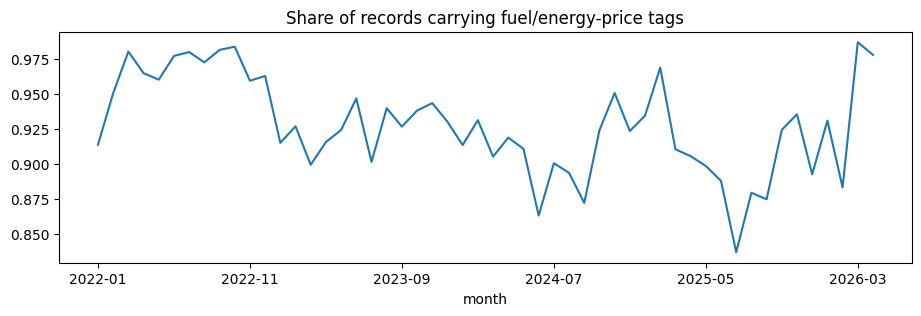

In [11]:
clustered_df = df[df['cluster'] >= 0].copy()

# 1) clustering-independent fuel-tag share
fuel_share = df.groupby('month')['is_fuel'].mean().rename('fuel_tag_share').sort_index()

# 2) theme shares (one series per theme)
theme_share = (clustered_df.groupby(['month', 'theme']).size()
               .unstack(fill_value=0))
theme_share = theme_share.div(theme_share.sum(axis=1), axis=0).sort_index()

# 3) mean tone of fuel-tagged records
fuel_tone = (df[df.is_fuel].groupby('month')['tone'].mean()
             .rename('fuel_tone').sort_index())

print(f'fuel_tag_share: {len(fuel_share)} months')
print(f'theme_share columns: {list(theme_share.columns)}')
print(f'fuel_tone: {len(fuel_tone)} months')
fuel_share.plot(figsize=(11,3), title='Share of records carrying fuel/energy-price tags');

## External validation , KBA registration shares (unchanged parsers)
FZ8 2022 PDFs + FZ8 2023-2026 xlsx -> diesel share; FZ28 -> BEV & hybrid shares.

In [12]:
!pip install "pdfplumber==0.11.10" "pillow>=12.2.0" -q
import glob, re , os
import pdfplumber

def parse_fz8_pdf(filepath):
    fname  = os.path.basename(filepath)
    match  = re.search(r'(\d{4})(\d{2})', fname)
    year, month = (match.group(1), match.group(2)) if match else ('0000','00')
    result = {'period': f'{year}-{month}'}

    def extract_nums(line):
        clean = re.sub(r'\s+r\s+', ' ', line)
        tokens = clean.split()
        nums, i = [], 0
        while i < len(tokens):
            if tokens[i].isdigit():
                if i + 1 < len(tokens) and re.match(r'^\d{3}$', tokens[i+1]):
                    val = int(tokens[i] + tokens[i+1])
                    if 100 <= val <= 999999:
                        nums.append(val); i += 2; continue
                val = int(tokens[i])
                if 100 <= val <= 999999:
                    nums.append(val)
            i += 1
        return nums

    with pdfplumber.open(filepath) as pdf:
        for page in pdf.pages:
            text = page.extract_text()
            if not text:
                continue
            if 'Zusammen' not in text or 'Elektro (BEV)' not in text or 'Hubraum' not in text:
                continue
            current_fuel = None
            for line in text.splitlines():
                line_s = re.sub(r'[\u00a0\u202f\u2009\u2007\u2008\u200a\u0020\t]+', ' ', line).strip()
                if line_s == 'Benzin':
                    current_fuel = 'benzin'; continue
                elif line_s == 'Diesel':
                    current_fuel = 'diesel'; continue
                nums = extract_nums(line_s)
                if not nums:
                    continue
                if line_s.startswith('Zusammen') and current_fuel in ('benzin', 'diesel'):
                    result.setdefault(current_fuel, nums[0]); current_fuel = None
                elif line_s.startswith('Elektro (BEV)'):
                    result.setdefault('bev', nums[0])
                elif line_s.startswith('Hybrid') and 'Plug' not in line_s and not line_s.startswith('dar'):
                    result.setdefault('hybrid', nums[0])
                elif line_s.startswith('dar. Plug-in'):
                    result.setdefault('phev', nums[0])
                elif line_s.startswith('Insgesamt'):
                    result.setdefault('total', nums[0])
    return result

pdf_records = []
for f in sorted(glob.glob(f'{KBA_FZ8_DIR}/2022/*.pdf')):
    try:
        rec = parse_fz8_pdf(f); pdf_records.append(rec)
        print(f'{rec["period"]}: benzin={rec.get("benzin","?")} diesel={rec.get("diesel","?")} '
              f'bev={rec.get("bev","?")} hybrid={rec.get("hybrid","?")} total={rec.get("total","?")}')
    except Exception as e:
        print(f'Error {os.path.basename(f)}: {e}')

pdf_df = pd.DataFrame(pdf_records).set_index('period').sort_index()
print(f'\nFZ8 2022 PDF months parsed: {len(pdf_df)}')
print(pdf_df)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.1/69.1 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 61.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 118.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 121.8 MB/s eta 0:00:00
2022-01: benzin=67575 diesel=39713 bev=20892 hybrid=54126 total=184112
2022-02: benzin=69195 diesel=41471 bev=28306 hybrid=59473 total=200512
2022-03: benzin=84123 diesel=45069 bev=34474 hybrid=75713 total=241330
2022-04: benzin=65030 diesel=35289 bev=22175 hybrid=56786 total=180264
2022-05: benzin=74573 diesel=42000 bev=29182 hybrid=60659 total=207199
2022-06: benzin=83175 diesel=42495 bev=32234 hybrid=65363 total=224558
2022-07: benzin=74094 diesel=41386 bev=28815 hybrid=59962 total=205911
2022-08: benzin=69441 diesel=363

In [13]:
def parse_kba_xlsx(filepath):
    fname = os.path.basename(filepath)
    match = re.search(r'(\d{4})_?(\d{2})(?:_|\.|$)', fname)
    year, month = (match.group(1), match.group(2)) if match else ('0000','00')
    result = {'period': f'{year}-{month}'}

    xl = pd.ExcelFile(filepath)
    target_sheet = next((s for s in xl.sheet_names if '8.5' in s), None)
    if target_sheet is None:
        print(f'  No FZ 8.5 sheet in {os.path.basename(filepath)}: {xl.sheet_names}')
        return result

    sheet = pd.read_excel(filepath, sheet_name=target_sheet, header=None, dtype=str)

    def first_num(vals, lo, hi):
        for v in vals:
            try:
                val = int(str(v).replace('.', '').replace(',', ''))
                if lo <= val <= hi:
                    return val
            except (ValueError, TypeError):
                continue
        return None

    current_fuel = None
    for _, row in sheet.iterrows():
        vals = [str(x).strip() for x in row.values if str(x).strip() != 'nan']
        if not vals: continue
        first = vals[0]
        if first == 'Benzin':   current_fuel = 'benzin'
        elif first == 'Diesel': current_fuel = 'diesel'
        elif first == 'Zusammen' and current_fuel in ('benzin','diesel'):
            v = first_num(vals[1:], 1000, 999999)
            if v is not None: result.setdefault(current_fuel, v)
            current_fuel = None
        elif first == 'Elektro (BEV)':
            v = first_num(vals[1:], 1000, 999999)
            if v is not None: result.setdefault('bev', v)
        elif first == 'Hybrid':
            v = first_num(vals[1:], 1000, 999999)
            if v is not None: result.setdefault('hybrid', v)
        elif first in ('darunter Plug-in', 'dar. Plug-in', 'Plug-in'):
            v = first_num(vals[1:], 100, 999999)
            if v is not None: result.setdefault('phev', v)
        elif first == 'Insgesamt':
            v = first_num(vals[1:], 10000, 999999)
            if v is not None: result.setdefault('total', v)
    return result

fz8_records = []
for f in sorted(glob.glob(f'{KBA_FZ8_DIR}/**/*.xlsx', recursive=True)):
    try:
        rec = parse_kba_xlsx(f); fz8_records.append(rec)
    except Exception as e:
        print(f'Error {os.path.basename(f)}: {e}')

kba_xlsx_df = pd.DataFrame(fz8_records).set_index('period').sort_index()
print(f'FZ8 xlsx months parsed: {len(kba_xlsx_df)}')

# Combine 2022 PDFs + 2023-2026 xlsx
for d in (pdf_df, kba_xlsx_df):
    d['diesel_share'] = d['diesel'] / d['total']
kba_combined = pd.concat([
    pdf_df[['diesel','bev','hybrid','phev','total','diesel_share']],
    kba_xlsx_df[['diesel','bev','hybrid','phev','total','diesel_share']],
]).sort_index()
kba_diesel = kba_combined['diesel_share'].dropna().sort_index()
print(f'\nKBA diesel-share series: {len(kba_diesel)} months, '
      f'{kba_diesel.index[0]} to {kba_diesel.index[-1]}')

FZ8 xlsx months parsed: 40

KBA diesel-share series: 52 months, 2022-01 to 2026-04


In [14]:
def parse_fz28_xlsx(filepath):
    fname = os.path.basename(filepath)
    match = re.search(r'(\d{4})_(\d{2})', fname)
    year, month = (match.group(1), match.group(2)) if match else ('0000','00')
    result = {'period': f'{year}-{month}'}

    xl = pd.ExcelFile(filepath)
    target_sheet = next((s for s in xl.sheet_names if '28.1' in s), None)
    if target_sheet is None:
        print(f'No FZ 28.1 sheet in {os.path.basename(filepath)}')
        return result

    sheet = pd.read_excel(filepath, sheet_name=target_sheet, header=None, dtype=str)

    def safe_int(val):
        try:
            v = int(str(val).replace('.', '').replace(',', '').strip())
            return v if v > 0 else None
        except (ValueError, TypeError):
            return None

    for _, row in sheet.iterrows():
        vals = [str(x).strip() for x in row.values]
        if len(vals) < 11 or vals[1] != 'Personenkraftwagen': continue
        if vals[2] == 'nan': continue
        result['total']  = safe_int(vals[2])
        result['bev']    = safe_int(vals[7])
        result['phev']   = safe_int(vals[9])
        result['hybrid'] = safe_int(vals[10])
        break
    return result

fz28_records = []
for f in sorted(glob.glob(f'{KBA_FZ28_DIR}/**/*.xlsx', recursive=True)):
    try:
        fz28_records.append(parse_fz28_xlsx(f))
    except Exception as e:
        print(f'Error {os.path.basename(f)}: {e}')

fz28_df = pd.DataFrame(fz28_records).set_index('period').sort_index()
fz28_df['bev_share']    = fz28_df['bev']    / fz28_df['total']
fz28_df['hybrid_share'] = fz28_df['hybrid'] / fz28_df['total']
kba_bev    = fz28_df['bev_share'].dropna().sort_index()
kba_hybrid = fz28_df['hybrid_share'].dropna().sort_index()
print(f'FZ28: {len(fz28_df)} months -> kba_bev {len(kba_bev)}, kba_hybrid {len(kba_hybrid)}')

FZ28: 52 months -> kba_bev 52, kba_hybrid 52


## Stage 3 , lead-lag analysis
ONE definition of each analysis function.
Positive lag = discourse leads registrations.

**Multiple-comparison note for the paper:** each lead-lag scan tests 13 lags, and we
run several discourse-vs-KBA pairs. Report the number of tests performed and treat
isolated significant lags with corresponding caution (e.g. Bonferroni-adjusted
threshold or explicit discussion). A null result under this discipline is a valid,
reportable finding per the course's falsifiability requirement.

In [15]:
import matplotlib.pyplot as plt

def lead_lag_analysis(discourse_series, kba_series, title, color='steelblue', plot=True):
    shared = discourse_series.index.intersection(kba_series.index)
    disc, kba_s = discourse_series[shared], kba_series[shared]
    lags, results = range(-6, 7), {}
    for lag in lags:
        shifted = disc.shift(lag)
        valid = shifted.notna()
        results[lag] = shifted[valid].corr(kba_s[valid]) if valid.sum() > 5 else np.nan
    if plot:
        plt.figure(figsize=(10, 3.5))
        plt.bar(list(results.keys()), list(results.values()), color=color)
        plt.xlabel('lag in months (positive = discourse leads)')
        plt.ylabel('correlation'); plt.title(title)
        plt.axhline(0, color='black', linewidth=0.8)
        plt.tight_layout(); plt.show()
    best = max(results, key=lambda k: abs(results[k]) if not np.isnan(results[k]) else 0)
    print(f'{title}\n  shared months: {len(shared)}, strongest |r| at lag {best:+d}, r = {results[best]:.3f}')
    return results, best


def bootstrap_ci(discourse_series, kba_series, n_bootstrap=BOOTSTRAP_N):
    """Block-free bootstrap over months of the best-|r| lag. NOTE for the paper:
    i.i.d. resampling of an autocorrelated time series is a simplification; state it
    as a limitation (a moving-block bootstrap is the stricter alternative)."""
    shared = discourse_series.index.intersection(kba_series.index)
    d_all, k_all = discourse_series[shared].values, kba_series[shared].values
    n, lags, boot_lags = len(shared), range(-6, 7), []
    for _ in range(n_bootstrap):
        idx = np.random.choice(n, size=n, replace=True)
        d, k = d_all[idx], k_all[idx]
        best_r, best_lag = -1, 0
        for lag in lags:
            if lag > 0 and len(d) > lag:      r = np.corrcoef(d[lag:], k[lag:])[0, 1]
            elif lag < 0 and len(d) > -lag:   r = np.corrcoef(d[:lag], k[:lag])[0, 1]
            else:                             r = np.corrcoef(d, k)[0, 1]
            if not np.isnan(r) and abs(r) > best_r:
                best_r, best_lag = abs(r), lag
        boot_lags.append(best_lag)
    return boot_lags, np.percentile(boot_lags, 2.5), np.percentile(boot_lags, 97.5)

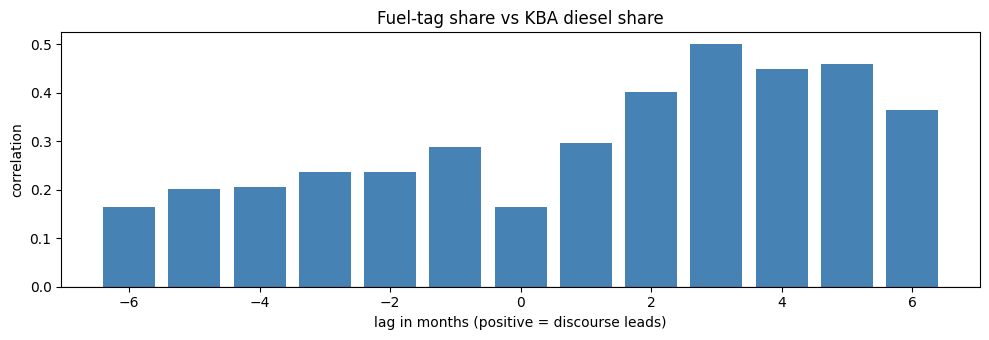

Fuel-tag share vs KBA diesel share
  shared months: 52, strongest |r| at lag +3, r = 0.500



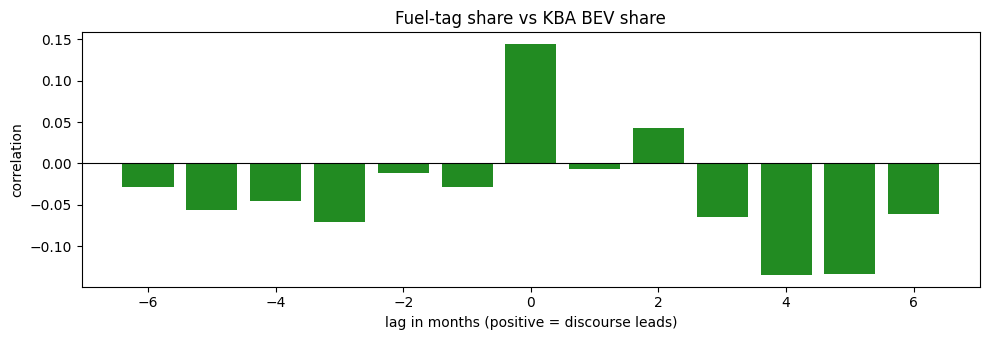

Fuel-tag share vs KBA BEV share
  shared months: 52, strongest |r| at lag +0, r = 0.144



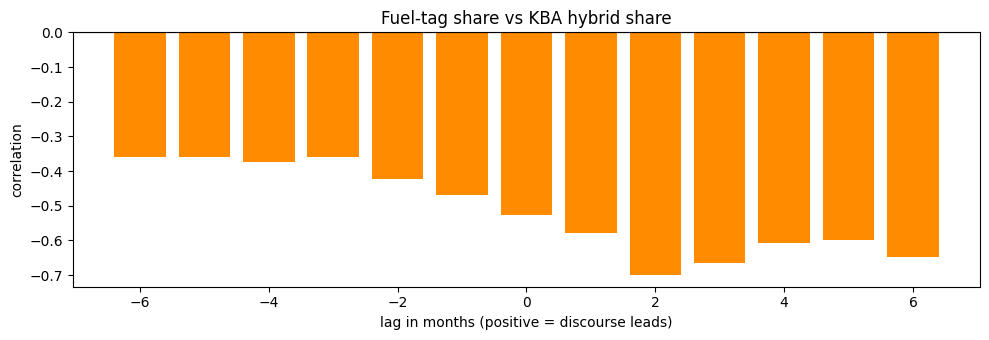

Fuel-tag share vs KBA hybrid share
  shared months: 52, strongest |r| at lag +2, r = -0.698



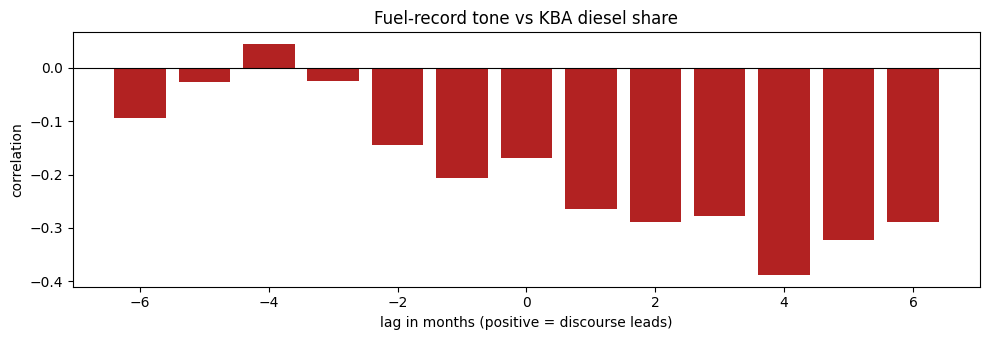

Fuel-record tone vs KBA diesel share
  shared months: 52, strongest |r| at lag +4, r = -0.389



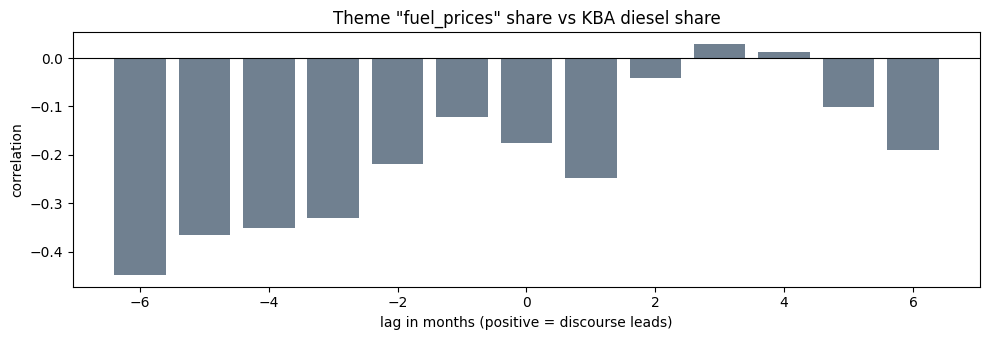

Theme "fuel_prices" share vs KBA diesel share
  shared months: 52, strongest |r| at lag -6, r = -0.448



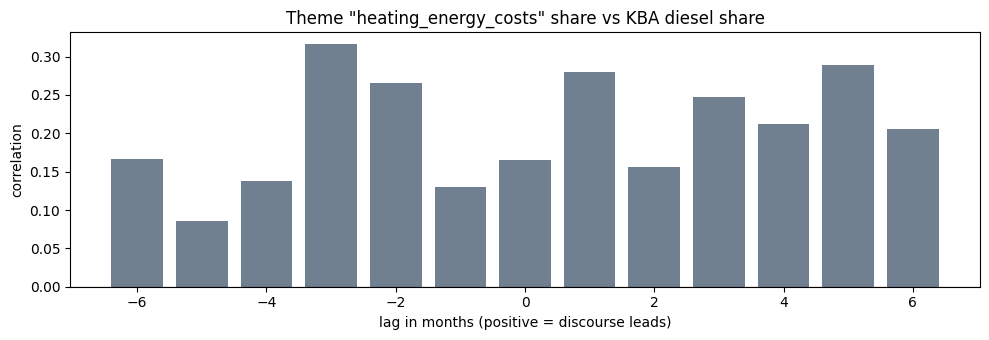

Theme "heating_energy_costs" share vs KBA diesel share
  shared months: 52, strongest |r| at lag -3, r = 0.316



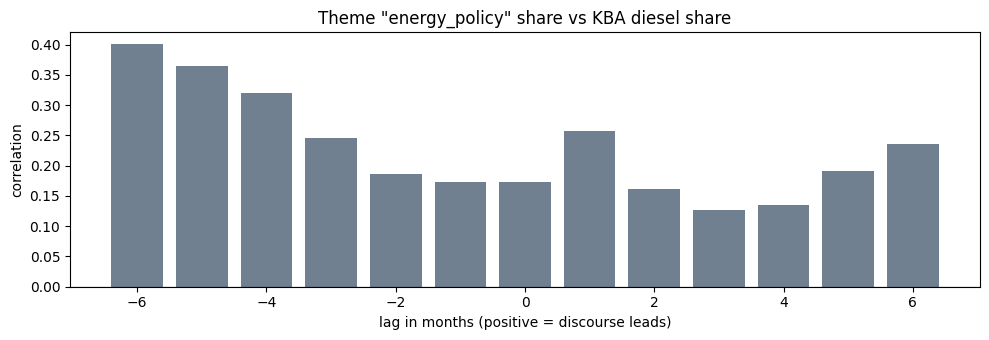

Theme "energy_policy" share vs KBA diesel share
  shared months: 52, strongest |r| at lag -6, r = 0.400



In [16]:
# --- Primary analysis: fuel-cost discourse vs KBA shares ---
pairs = [
    ('Fuel-tag share vs KBA diesel share', fuel_share, kba_diesel, 'steelblue'),
    ('Fuel-tag share vs KBA BEV share',    fuel_share, kba_bev,    'forestgreen'),
    ('Fuel-tag share vs KBA hybrid share', fuel_share, kba_hybrid, 'darkorange'),
    ('Fuel-record tone vs KBA diesel share', fuel_tone, kba_diesel, 'firebrick'),
]
# Secondary: labeled theme shares that exist in this run
for theme in ['fuel_prices', 'heating_energy_costs', 'energy_policy']:
    if theme in theme_share.columns:
        pairs.append((f'Theme "{theme}" share vs KBA diesel share',
                      theme_share[theme], kba_diesel, 'slategray'))

lead_lag_results = {}
for title, disc, kba_s, color in pairs:
    lead_lag_results[title] = lead_lag_analysis(disc, kba_s, title, color)
    print()

In [17]:
# --- Bootstrap CIs for the primary pairs ---
np.random.seed(SEED)
print(f'Bootstrap 95% CIs of the best lag (n={BOOTSTRAP_N}):')
ci_table = {}
for title, disc, kba_s, _ in pairs[:4]:
    _, lo, hi = bootstrap_ci(disc, kba_s)
    ci_table[title] = (lo, hi)
    print(f'  {title:50s} [{lo:+.1f}, {hi:+.1f}]')
print('\nA CI spanning the full [-6, +6] range means the lead time is not identified '
      'at this sample size , report that honestly.')

Bootstrap 95% CIs of the best lag (n=1000):
  Fuel-tag share vs KBA diesel share                 [-6.0, +6.0]
  Fuel-tag share vs KBA BEV share                    [-6.0, +6.0]
  Fuel-tag share vs KBA hybrid share                 [-6.0, +6.0]
  Fuel-record tone vs KBA diesel share               [-6.0, +6.0]

A CI spanning the full [-6, +6] range means the lead time is not identified at this sample size — report that honestly.


## Stage 3b , stationarity, and why it changes the answer

The lead-lag and Granger tests above assume both series are stationary. A
series that trends violates that assumption, and correlating two trending
series produces significance that reflects the shared trend rather than any
relationship between them. Granger and Newbold (1974) showed that independent
random walks test "significant" at p < 0.05 roughly three quarters of the time.

Our discourse volume falls across the window as the 2022 energy shock fades,
while the hybrid registration share rises as electrification proceeds. Two
opposing trends will correlate strongly whatever the underlying mechanism.

We therefore test every series with the augmented Dickey-Fuller (ADF) test,
first-difference before inference, and report both the level and the
differenced results so the size of the correction is visible.

In [18]:
# =====================================================================
# Stage 3b.1 , ADF stationarity tests on the LEVEL series
# H0: the series has a unit root (is non-stationary).
# p < 0.05 => reject H0 => stationary.
# =====================================================================
from statsmodels.tsa.stattools import adfuller

ALPHA = 0.05

def adf_report(series, name, alpha=ALPHA):
    """Run ADF with AIC-selected lag order and print a one-line verdict."""
    s = pd.Series(series).dropna().astype(float)
    stat, p, used_lag, nobs, crit, _ = adfuller(s, autolag='AIC')
    verdict = 'stationary' if p < alpha else 'NON-stationary'
    print(f'  {name:26s} ADF={stat:7.3f}  p={p:6.4f}  '
          f'lags={used_lag:2d}  n={nobs:2d}  -> {verdict}')
    return p

print('ADF tests on LEVEL series')
print('(H0: unit root. p < 0.05 => stationary)\n')

level_series = {
    'fuel_tag_share'  : fuel_share,
    'fuel_tone'       : fuel_tone,
    'kba_diesel_share': kba_diesel,
    'kba_bev_share'   : kba_bev,
    'kba_hybrid_share': kba_hybrid,
}
for th in theme_share.columns:
    level_series[f'theme:{th}'] = theme_share[th]

adf_levels = {k: adf_report(v, k) for k, v in level_series.items()}

nonstat = [k for k, p in adf_levels.items() if p >= ALPHA]
print(f'\n{len(nonstat)} of {len(adf_levels)} series are non-stationary:')
for k in nonstat:
    print(f'  - {k}')
print('\nGranger causality on non-stationary series risks spurious regression')
print('(Granger & Newbold 1974). All series are first-differenced below.')

ADF tests on LEVEL series
(H0: unit root. p < 0.05 => stationary)

  fuel_tag_share             ADF= -3.366  p=0.0122  lags= 0  n=51  -> stationary
  fuel_tone                  ADF= -2.971  p=0.0377  lags=11  n=40  -> stationary
  kba_diesel_share           ADF=  1.701  p=0.9981  lags=11  n=40  -> NON-stationary
  kba_bev_share              ADF= -2.962  p=0.0386  lags= 1  n=50  -> stationary
  kba_hybrid_share           ADF= -1.376  p=0.5938  lags= 7  n=44  -> NON-stationary
  theme:accidents_safety     ADF= -4.212  p=0.0006  lags= 0  n=51  -> stationary
  theme:energy_policy        ADF= -4.506  p=0.0002  lags= 0  n=51  -> stationary
  theme:fuel_prices          ADF= -4.841  p=0.0000  lags= 0  n=51  -> stationary
  theme:heating_energy_costs ADF= -6.215  p=0.0000  lags= 0  n=51  -> stationary
  theme:road_transport       ADF= -5.124  p=0.0000  lags= 0  n=51  -> stationary

2 of 10 series are non-stationary:
  - kba_diesel_share
  - kba_hybrid_share

Granger causality on non-stationary 

In [19]:
# =====================================================================
# Stage 3b.2 , Granger causality, LEVELS vs FIRST-DIFFERENCED
#
# We report both. The level column reproduces the naive result the starter
# notebook's Stage 3 produces; the differenced column is the valid inference.
# The gap between them is a finding, not an embarrassment.
#
# Uniform first-differencing is applied to every pair. Differencing an
# already-stationary series costs a little efficiency but introduces no bias,
# and keeps the treatment identical across all pairs, which makes the table
# directly comparable.
# =====================================================================
from statsmodels.tsa.stattools import grangercausalitytests

MAXLAG = 4

def granger_pvalues(discourse, kba_series, maxlag=MAXLAG, difference=True):
    """SSR-based F-test p-value per lag. Returns (dict, n_used)."""
    idx = discourse.index.intersection(kba_series.index)
    d = pd.Series(discourse[idx]).astype(float)
    k = pd.Series(kba_series[idx]).astype(float)
    if difference:
        d, k = d.diff(), k.diff()
    g = pd.DataFrame({'kba': k, 'discourse': d}).dropna()
    res = grangercausalitytests(g[['kba', 'discourse']],
                                maxlag=maxlag, verbose=False)
    return {lag: res[lag][0]['ssr_ftest'][1] for lag in res}, len(g)


# The pairs tested. Extend with theme_share columns if you report them.
granger_pairs = [
    ('fuel-tag share', 'diesel', fuel_share, kba_diesel),
    ('fuel-tag share', 'BEV',    fuel_share, kba_bev),
    ('fuel-tag share', 'hybrid', fuel_share, kba_hybrid),
    ('fuel tone',      'diesel', fuel_tone,  kba_diesel),
]

granger_results = {}
header = f"{'pair':38s} {'n':>3}  " + "  ".join(f'L{l}' for l in range(1, MAXLAG + 1))
print(header)
print('-' * len(header))

for dn, kn, ds, ks in granger_pairs:
    for diff_mode in (False, True):
        pvals, n = granger_pvalues(ds, ks, difference=diff_mode)
        tag = 'differenced' if diff_mode else 'levels     '
        label = f'{dn} -> {kn} [{tag}]'
        print(f'{label:38s} {n:3d}  ' +
              "  ".join(f'{pvals[l]:.3f}' for l in range(1, MAXLAG + 1)))
        granger_results[(dn, kn, diff_mode)] = pvals
    print()

# --- multiple-comparison accounting -------------------------------------
n_tests = len(granger_pairs) * MAXLAG
bonf = 0.05 / n_tests
diff_ps = [p for (dn, kn, m), d in granger_results.items() if m
           for p in d.values()]
lvl_ps  = [p for (dn, kn, m), d in granger_results.items() if not m
           for p in d.values()]

print(f'Granger tests per transformation : {n_tests}')
print(f'Bonferroni-corrected threshold   : {bonf:.4f}')
print(f'Smallest p, LEVELS               : {min(lvl_ps):.4f}')
print(f'Smallest p, DIFFERENCED          : {min(diff_ps):.4f}')
print()
if min(diff_ps) < bonf:
    print('A differenced result survives correction. Report it.')
else:
    print('No differenced result survives Bonferroni correction.')
    print('The falsifiable threshold is NOT met -> report a null.')

pair                                     n  L1  L2  L3  L4
----------------------------------------------------------
fuel-tag share -> diesel [levels     ]  52  0.132  0.250  0.110  0.181
fuel-tag share -> diesel [differenced]  51  0.716  0.347  0.370  0.512

fuel-tag share -> BEV [levels     ]     52  0.758  0.818  0.480  0.464
fuel-tag share -> BEV [differenced]     51  0.514  0.183  0.244  0.372

fuel-tag share -> hybrid [levels     ]  52  0.178  0.033  0.067  0.067
fuel-tag share -> hybrid [differenced]  51  0.569  0.279  0.080  0.229

fuel tone -> diesel [levels     ]       52  0.259  0.713  0.798  0.532
fuel tone -> diesel [differenced]       51  0.410  0.491  0.427  0.503

Granger tests per transformation : 16
Bonferroni-corrected threshold   : 0.0031
Smallest p, LEVELS               : 0.0329
Smallest p, DIFFERENCED          : 0.0798

No differenced result survives Bonferroni correction.
The falsifiable threshold is NOT met -> report a null.


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print resul

### Differenced lead-lag and bootstrap

Supplies the differenced correlation and CI columns reported in the paper.


In [ ]:
# =====================================================================
# Differenced lead-lag correlations and differenced bootstrap CIs.
# Reuses lead_lag_analysis() and bootstrap_ci() defined above, applied to
# first-differenced series. Supplies the "Differenced" columns of the
# best-lag table in the paper, which the level-only calls above do not.
# =====================================================================
diff = lambda s: s.diff().dropna()

pairs_diff = [
    ('Fuel-tag share vs KBA diesel share', fuel_share, kba_diesel),
    ('Fuel-tag share vs KBA BEV share',    fuel_share, kba_bev),
    ('Fuel-tag share vs KBA hybrid share', fuel_share, kba_hybrid),
    ('Fuel-record tone vs KBA diesel share', fuel_tone, kba_diesel),
]

np.random.seed(SEED)
print('DIFFERENCED lead-lag and bootstrap (first differences of both series)\n')
print(f"{'pair':40s} {'lag':>4} {'r':>8}   95% CI")
print('-' * 72)
diff_results = {}
for title, disc, kba_s in pairs_diff:
    dd, kk = diff(disc), diff(kba_s)
    res, best = lead_lag_analysis(dd, kk, title, plot=False)
    _, lo, hi = bootstrap_ci(dd, kk)
    diff_results[title] = (best, res[best], lo, hi)
    print(f'{title:40s} {best:+4d} {res[best]:+8.3f}   [{lo:+.1f}, {hi:+.1f}]')

print('\nCIs are computed on the differenced series, matching the paper.')
print('Note: i.i.d. month resampling of an autocorrelated series is a')
print('simplification; a moving-block bootstrap is the stricter alternative.')


In [20]:
# =====================================================================
# Export the differenced Granger grid as LaTeX table rows
# =====================================================================
print('% --- paste into the Granger table in the .tex ---')
for (dn, kn, diff_mode), pvals in granger_results.items():
    if not diff_mode:
        continue
    cells = ' & '.join(f'{pvals[l]:.3f}' for l in range(1, MAXLAG + 1))
    print(f'{dn} $\\rightarrow$ {kn} & {cells} \\\\')
print(f'% Bonferroni threshold for {n_tests} tests: {bonf:.4f}')

% --- paste into the Granger table in the .tex ---
fuel-tag share $\rightarrow$ diesel & 0.716 & 0.347 & 0.370 & 0.512 \\
fuel-tag share $\rightarrow$ BEV & 0.514 & 0.183 & 0.244 & 0.372 \\
fuel-tag share $\rightarrow$ hybrid & 0.569 & 0.279 & 0.080 & 0.229 \\
fuel tone $\rightarrow$ diesel & 0.410 & 0.491 & 0.427 & 0.503 \\
% Bonferroni threshold for 16 tests: 0.0031


## Stage 3c. Cointegration check

Justifies first-differencing rather than a vector error-correction model.


In [ ]:
# =====================================================================
# Johansen cointegration test.
# Differencing is the right estimator only if the non-stationary pairs do
# not share a long-run relationship. If they were cointegrated, a VECM
# would preserve information that differencing throws away. Reported in
# Section V.D of the paper.
# =====================================================================
from statsmodels.tsa.vector_ar.vecm import coint_johansen

print('JOHANSEN TRACE TEST (non-stationary outcome pairs only)\n')
for name, ks in [('diesel share', kba_diesel), ('hybrid share', kba_hybrid)]:
    idx = fuel_share.index.intersection(ks.index)
    m = pd.DataFrame({'discourse': fuel_share[idx].astype(float),
                      'kba': ks[idx].astype(float)}).dropna()
    j = coint_johansen(m.values, det_order=0, k_ar_diff=1)
    print(f'fuel-tag share vs {name}  (n={len(m)})')
    for r in range(len(j.lr1)):
        verdict = 'reject H0' if j.lr1[r] > j.cvt[r, 1] else 'cannot reject H0'
        print(f'  r<={r}: trace={j.lr1[r]:6.3f}   95% crit={j.cvt[r, 1]:6.3f}'
              f'   -> {verdict}')
    print()
print('H0 at r<=0 is "no cointegrating relationship".')
print('Not rejecting it means first-differencing is appropriate, not a compromise.')


### Retained for reference only. Not the reported analysis.

The cell below is the original Stage 3 Granger call on **level** series. It is
superseded by the stationarity-aware analysis above, which reports levels and
first differences side by side and applies the Bonferroni correction over the
declared sixteen-test family. The results reported in the paper come from that
analysis, not from this cell. This cell is kept only to document the original
run.


In [21]:
from statsmodels.tsa.stattools import grangercausalitytests

def granger_test(discourse_series, kba_series, label, maxlag=4):
    shared = discourse_series.index.intersection(kba_series.index)
    g_df = pd.DataFrame({'kba': kba_series[shared].values,
                         'discourse': discourse_series[shared].values}, index=shared)
    g_df = g_df.dropna()
    print(f'\n--- Granger: does discourse predict {label}? (n={len(g_df)}) ---')
    print('NOTE: %d lags tested here; account for multiple testing in the paper.' % maxlag)
    try:
        grangercausalitytests(g_df[['kba', 'discourse']], maxlag=maxlag)
    except Exception as e:
        print('Granger test failed:', e)

granger_test(fuel_share, kba_diesel, 'diesel share')
granger_test(fuel_share, kba_bev,    'BEV share')
granger_test(fuel_share, kba_hybrid, 'hybrid share')
granger_test(fuel_tone,  kba_diesel, 'diesel share (tone)')


--- Granger: does discourse predict diesel share? (n=52) ---
NOTE: 4 lags tested here; account for multiple testing in the paper.

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=2.3513  , p=0.1317  , df_denom=48, df_num=1
ssr based chi2 test:   chi2=2.4983  , p=0.1140  , df=1
likelihood ratio test: chi2=2.4390  , p=0.1183  , df=1
parameter F test:         F=2.3513  , p=0.1317  , df_denom=48, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=1.4314  , p=0.2497  , df_denom=45, df_num=2
ssr based chi2 test:   chi2=3.1808  , p=0.2038  , df=2
likelihood ratio test: chi2=3.0838  , p=0.2140  , df=2
parameter F test:         F=1.4314  , p=0.2497  , df_denom=45, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=2.1355  , p=0.1101  , df_denom=42, df_num=3
ssr based chi2 test:   chi2=7.4742  , p=0.0582  , df=3
likelihood ratio test: chi2=6.9562  , p=0.0733  , df=3
parameter F test:         F=2.1355  , p=0

## Results summary and reporting discipline

Fill the table from the outputs above. Reporting rules for the paper:

1. **State the number of tests.** 13 lags x N series pairs for lead-lag, plus 4 lags x 4
   Granger pairs. One p < 0.05 among ~20+ tests is expected under the null , apply a
   correction or discuss it explicitly.
2. **A null is a finding.** If fuel-cost discourse does not significantly lead KBA shares,
   report the falsifiable threshold as not met. The topic catalogue explicitly defines
   this outcome as a valid study result.
3. **Three runs.** Executed under SEED = 1234, 5678 and 9012. Grammar-constrained
   decoding at temperature 0 makes the labelling deterministic, so the three runs
   return identical community labels. The determinism cell above records this.
   Note the discourse series used for inference (fuel-tag share and fuel-record
   tone) are built from GDELT tags directly and never touch the classifier, so
   the Granger, ADF and Johansen results are seed-independent by construction.
4. **Methodology paragraph.** Corpus rescope rationale (powertrain-term counts), theme-family
   stripping rule, DF_MAX cutoff, THRESHOLD, MIN_COMMUNITY_SIZE, EMBED_MODEL, SEED,
   the theme enum verbatim, and the prompt verbatim.

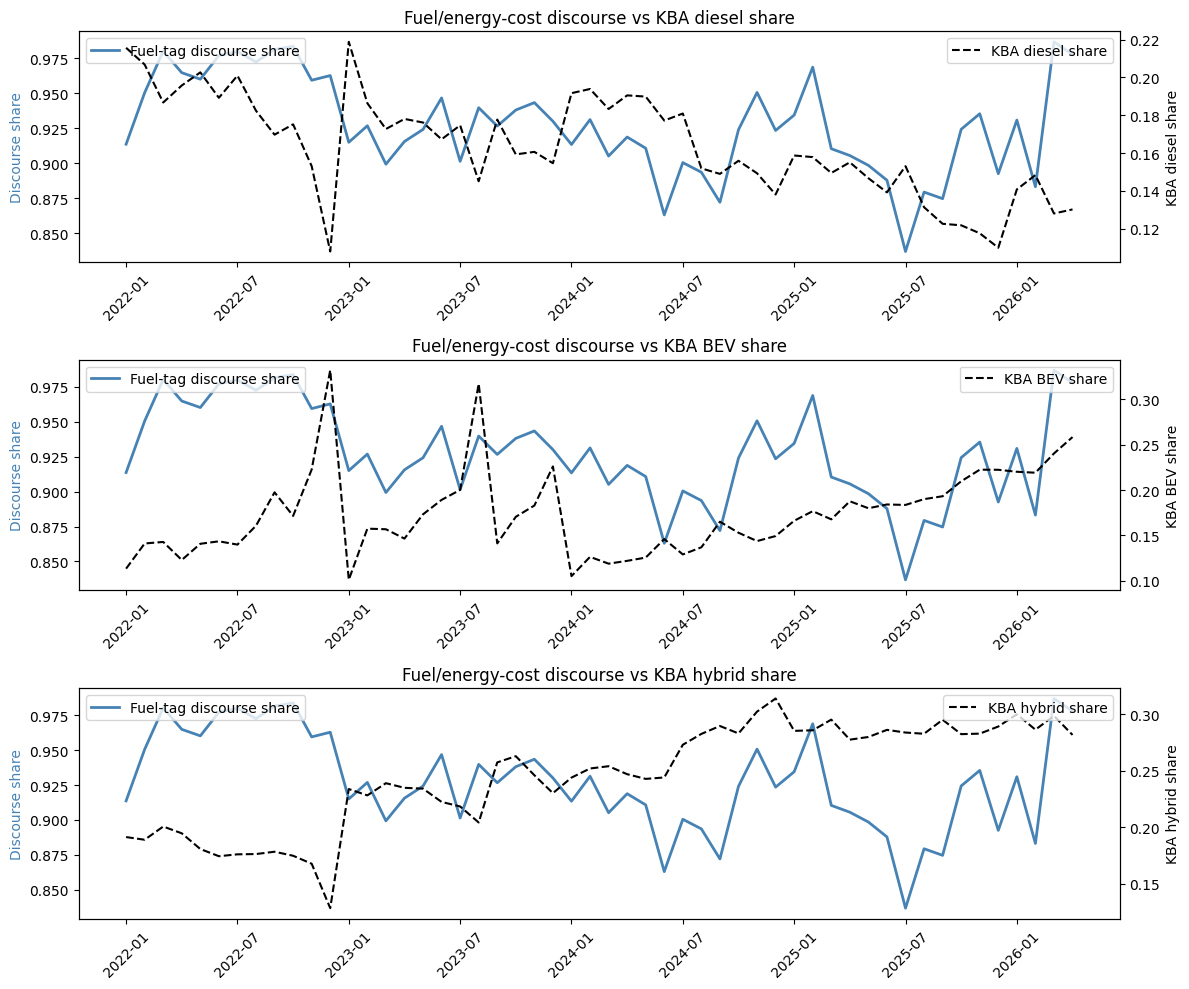

Pipeline complete. Reruns: SEED = 5678, 9012 from the embedding cell onward.


In [22]:
# Final visual: primary discourse series vs the three KBA shares
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for ax, (title, kba_s) in zip(axes, [('KBA diesel share', kba_diesel),
                                     ('KBA BEV share', kba_bev),
                                     ('KBA hybrid share', kba_hybrid)]):
    shared = fuel_share.index.intersection(kba_s.index)
    ax2 = ax.twinx()
    ax.plot(range(len(shared)), fuel_share[shared].values, color='steelblue',
            linewidth=2, label='Fuel-tag discourse share')
    ax2.plot(range(len(shared)), kba_s[shared].values, color='black',
             linewidth=1.5, linestyle='--', label=title)
    ax.set_title(f'Fuel/energy-cost discourse vs {title}')
    ax.set_ylabel('Discourse share', color='steelblue')
    ax2.set_ylabel(title)
    ax.set_xticks(range(0, len(shared), 6))
    ax.set_xticklabels(list(shared)[::6], rotation=45)
    ax.legend(loc='upper left'); ax2.legend(loc='upper right')
plt.tight_layout(); plt.show()

print('Pipeline complete. Reruns: SEED = 5678, 9012 from the embedding cell onward.')